# ÖDEV: Derin Öğrenme ve Evrişimsel Sinir Ağlarının (CNN) Temel Yapısının İncelenmesi

**Programlama dili:** Python  **Kütüphane:** TensorFlow / Keras  **Veri seti:** Fashion-MNIST

## 1. Ödevin amacı
Bu çalışmada yalnızca çalışan bir CNN modeli kurmakla kalmayıp, modeli oluşturan her katmanın (Conv2D, MaxPooling, ReLU, Flatten, Dense, Softmax) ne iş yaptığını, giriş/çıkış boyutlarını ve veri üzerinde yaptığı işlemi adım adım inceliyoruz. Önce teorik kavramlar cevaplanmış, ardından her kavram küçük kod örnekleriyle doğrulanmış, en sonda Fashion-MNIST üzerinde bir CNN eğitilip filtre sayısıyla ilgili küçük bir deney yapılmıştır.

İçerik:
1. Yapay sinir ağlarının temel çalışma prensibi
2. Konvolüsyon katmanı, filtre (kernel) ve ağırlık kavramları
3. Max Pooling katmanı
4. ReLU ve Softmax aktivasyon fonksiyonları
5. Flatten ve Dense katmanları
6. CNN mimarisinin oluşturulması, eğitilmesi ve deney

In [1]:
# Ortak kütüphaneler ve çıktı klasörü
import os, time, json
os.environ["TF_CPP_MIN_LOG_LEVEL"] = "2"   # TensorFlow uyarı kalabalığını azalt
import numpy as np
import tensorflow as tf
import matplotlib.pyplot as plt

os.makedirs("ciktilar", exist_ok=True)     # Grafikler bu klasöre kaydedilir
print("TensorFlow sürümü:", tf.__version__)

TensorFlow sürümü: 2.21.0


## 2. Bölüm: Temel kavramların incelenmesi

### Soru 1. Derin öğrenme nedir?

**Makine öğrenmesi ile derin öğrenme arasındaki fark nedir?**
Makine öğrenmesi, bilgisayarın açıkça programlanmadan veriden örüntü öğrenmesini sağlayan genel alandır. Klasik makine öğrenmesi yöntemlerinde (karar ağacı, SVM, KNN vb.) genellikle özellikleri (feature) insan belirler; örneğin bir görüntü için kenar sayısı, renk histogramı gibi değerler elle çıkarılıp modele verilir. Derin öğrenme ise makine öğrenmesinin bir alt dalıdır ve çok katmanlı yapay sinir ağları kullanır. En önemli farkı, özellikleri **kendisinin öğrenmesidir**: ham pikselleri alır, ilk katmanlarda kenar/çizgi gibi basit, sonraki katmanlarda şekil ve nesne parçası gibi karmaşık özellikleri otomatik olarak çıkarır. Bunun karşılığında daha fazla veriye ve hesaplama gücüne (GPU) ihtiyaç duyar.

**Yapay sinir ağı nasıl çalışır?**
Yapay sinir ağı, nöron adı verilen basit hesaplama birimlerinden oluşur. Her nöron girişlerini ağırlıklarla çarpar, toplar, bir bias (sapma) değeri ekler ve sonucu bir aktivasyon fonksiyonundan geçirir: $y = f(\sum_i w_i x_i + b)$. Veri katman katman ilerler (**ileri yayılım**), ağın tahmini gerçek etiketle karşılaştırılarak bir **kayıp (loss)** hesaplanır. Ardından **geri yayılım (backpropagation)** ile kaybın her ağırlığa göre türevi (gradyan) bulunur ve bir optimizasyon algoritması (ör. Adam, SGD) ağırlıkları kaybı azaltacak yönde küçük adımlarla günceller. Bu işlem binlerce örnek üzerinde tekrarlanarak ağ "öğrenir".

**Bir yapay sinir ağı neden birden fazla katmandan oluşur?**
Tek katmanlı bir ağ yalnızca doğrusal (lineer) ayrılabilen problemleri çözebilir (ör. XOR problemini çözemez). Araya doğrusal olmayan aktivasyonlu gizli katmanlar eklendiğinde ağ çok daha karmaşık fonksiyonları temsil edebilir. Ayrıca her katman bir öncekinin çıkardığı özellikleri birleştirerek daha soyut bir temsil oluşturur: piksel → kenar → doku/şekil → nesne parçası → nesne. Bu **hiyerarşik özellik öğrenme**, derin ağları görüntü, ses ve dil gibi karmaşık verilerde başarılı kılar.

### Soru 2. Konvolüsyon nedir?

**Konvolüsyon işlemi görüntü üzerinde nasıl gerçekleştirilir?**
Küçük bir ağırlık matrisi (filtre) görüntünün sol üst köşesine yerleştirilir. Filtrenin altında kalan piksellerle filtre ağırlıkları eleman eleman çarpılır, sonuçlar toplanır ve bias eklenir; bu tek sayı çıkış haritasının (feature map) bir pikseli olur. Sonra filtre bir adım (stride) kaydırılır ve işlem tüm görüntü taranana kadar tekrarlanır. Sonuçta, filtrenin aradığı desenin görüntüde nerelerde bulunduğunu gösteren bir **özellik haritası** elde edilir.

**Kernel (filtre) nedir?**
Kernel, değerleri eğitim sırasında öğrenilen küçük bir ağırlık matrisidir (ör. 3×3). Her filtre belirli bir deseni yakalamaya özelleşir: biri dikey kenarları, biri yatay kenarları, biri belirli bir dokuyu algılayabilir. Klasik görüntü işlemede bu filtreler (Sobel vb.) elle tasarlanırken, CNN'de veriye bakarak otomatik öğrenilir.

**3×3 boyutundaki bir filtrenin kaç ağırlık parametresi vardır?**
Tek kanallı (gri seviyeli) giriş için 3×3 = **9 ağırlık** + 1 bias = 10 parametre vardır. Giriş C kanallı ise filtre aslında 3×3×C boyutundadır ve 9·C ağırlık + 1 bias içerir (ör. RGB görüntüde 27 + 1 = 28).

**Filtre görüntü üzerinde hareket ederken ne yapar?**
Her konumda altında kalan bölge ile kendi ağırlıkları arasında nokta çarpımı yapar; yani o bölgenin filtrenin aradığı desene ne kadar benzediğini ölçer. Benzerlik yüksekse çıkış değeri büyük olur. Önemli nokta, filtrenin **aynı ağırlıkları tüm konumlarda paylaşmasıdır** (weight sharing); böylece bir desen görüntünün neresinde olursa olsun aynı filtreyle bulunur ve parametre sayısı çok düşük kalır.

**Bir CNN'de neden birden fazla filtre kullanılır?**
Tek bir filtre yalnızca tek tip deseni algılayabilir. Bir görüntüyü tanımak için ise farklı yönlerde kenarlar, köşeler, dokular gibi pek çok farklı özelliğe ihtiyaç vardır. Her filtre ayrı bir özellik haritası üretir; 16 filtre kullanmak, görüntünün 16 farklı "bakış açısıyla" incelenmesi demektir. Bu haritalar üst üste konarak çıkışın kanal (derinlik) boyutunu oluşturur.

### Soru 3. Pooling nedir?

**Max Pooling işleminin amacı nedir?**
Özellik haritalarının uzamsal boyutunu (genişlik/yükseklik) küçültmek, böylece hesaplama yükünü ve parametre sayısını azaltmaktır. Aynı zamanda her bölgedeki en güçlü yanıtı koruyarak önemli bilgiyi saklar, küçük kaymalara karşı modeli daha dayanıklı (öteleme değişmezliği) yapar ve aşırı öğrenmeyi (overfitting) azaltmaya yardımcı olur. Pooling katmanının öğrenilen parametresi yoktur.

**2×2 Max Pooling nasıl çalışır?**
Özellik haritası örtüşmeyen 2×2'lik bloklara bölünür (stride = 2). Her bloktaki 4 sayıdan en büyüğü seçilir ve çıkışa yazılır; diğer üçü atılır.

**Giriş görüntüsünün boyutunu nasıl değiştirir?**
Yüksekliği ve genişliği yarıya indirir, kanal sayısını değiştirmez. Örneğin 26×26×8 → 13×13×8 olur. Böylece piksel sayısı 4'te 1'e düşer. Tek sayılı boyutlarda kalan son satır/sütun atılır (11×11 → 5×5).

### Soru 4. Aktivasyon fonksiyonları

**Aktivasyon fonksiyonları neden kullanılır?**
Ağa **doğrusal olmama** (non-linearity) katmak için. Aktivasyon olmasaydı art arda gelen katmanların hepsi tek bir doğrusal dönüşüme indirgenirdi; ağ ne kadar derin olursa olsun bir doğrusal modelden farkı kalmazdı. Aktivasyonlar sayesinde ağ eğri karar sınırları ve karmaşık ilişkiler öğrenebilir.

**ReLU fonksiyonu nasıl çalışır?**
$\text{ReLU}(x) = \max(0, x)$. Negatif girişleri 0 yapar, pozitif girişleri olduğu gibi bırakır. Hesaplaması çok ucuzdur, pozitif bölgede türevi 1 olduğu için sigmoid/tanh'taki **kaybolan gradyan** problemini büyük ölçüde azaltır ve nöronların bir kısmını sıfırlayarak seyrek (sparse) temsiller oluşturur.

**Softmax fonksiyonu ne işe yarar?**
Bir vektördeki ham skorları (logit) toplamı 1 olan olasılıklara çevirir: $\text{softmax}(z_i) = \dfrac{e^{z_i}}{\sum_j e^{z_j}}$. Çok sınıflı sınıflandırmada çıkış katmanında kullanılır; her değer, girişin o sınıfa ait olma olasılığını ifade eder.

**ReLU ile Softmax arasındaki temel fark nedir?**
ReLU her elemana **bağımsız** uygulanır, çıkış aralığı [0, ∞)'dur ve gizli katmanlarda doğrusal olmama sağlamak için kullanılır. Softmax ise **tüm vektöre birlikte** uygulanır (bir elemanın sonucu diğerlerine bağlıdır), çıkışlar (0, 1) aralığındadır ve toplamları 1'dir; yalnızca çıkış katmanında sınıf olasılıklarını üretmek için kullanılır.

### Soru 5. Dense katman

**Dense katman nedir?**
Tam bağlantılı (fully connected) katmandır: katmandaki her nöron, bir önceki katmandaki **tüm** nöronlara bağlıdır. Çıkışı $y = f(W x + b)$ ile hesaplanır. N girişli ve M nöronlu bir Dense katmanda N·M ağırlık + M bias bulunur.

**Flatten katmanının görevi nedir?**
Konvolüsyon/pooling katmanlarından gelen çok boyutlu tensörü (ör. 5×5×16) tek boyutlu bir vektöre (5·5·16 = 400 eleman) dönüştürmektir. Dense katman tek boyutlu giriş beklediği için bu "düzleştirme" köprü görevi görür. Öğrenilen parametresi yoktur; yalnızca veriyi yeniden şekillendirir.

**CNN mimarisinde Dense katmanlar neden kullanılır?**
Konvolüsyon katmanları görüntüden yerel özellikleri çıkarır ("ne var, nerede var"). Dense katmanlar ise bu özelliklerin hepsini bir arada değerlendirip birleştirerek nihai **karar** verir ("bu özelliklerin birleşimi bir ayakkabıdır"). Yani konvolüsyon kısmı *özellik çıkarıcı*, Dense kısmı *sınıflandırıcı* olarak çalışır. Son Dense katman, sınıf sayısı kadar nöronla softmax üzerinden olasılıkları üretir.

## 3. Bölüm: Konvolüsyon işleminin kodlanması

In [2]:
import tensorflow as tf
import numpy as np

# Rastgelelik kontrolü
tf.keras.utils.set_random_seed(42)

# 3x3 boyutunda 16 filtreli konvolüsyon katmanı
conv = tf.keras.layers.Conv2D(
    filters=16,
    kernel_size=(3, 3),
    activation='relu',
    kernel_initializer='he_normal'
)

# Örnek giriş görüntüsü
dummy_input = tf.random.normal((1, 128, 128, 1))

# Konvolüsyon işlemi
output = conv(dummy_input)

# Ağırlıkları al
weights, biases = conv.get_weights()

print("Giriş boyutu:", dummy_input.shape)
print("Çıkış boyutu:", output.shape)
print("Filtre ağırlıklarının boyutu:", weights.shape)
print("Bias boyutu:", biases.shape)

# İlk filtrenin ağırlıkları
print("İlk filtre:")
print(weights[:, :, 0, 0])

Giriş boyutu: (1, 128, 128, 1)
Çıkış boyutu: (1, 126, 126, 16)
Filtre ağırlıklarının boyutu: (3, 3, 1, 16)
Bias boyutu: (16,)
İlk filtre:
[[-0.25283593  0.12861036 -0.75786656]
 [-0.21681367 -0.15182823 -0.702172  ]
 [ 0.23038778  0.76512676 -0.74278826]]


### Yapılacak çalışmalar – cevaplar

**1. Kodda kullanılan 16 filtre ne anlama gelmektedir?**
Katmanın birbirinden bağımsız 16 farklı 3×3 filtre öğreneceği anlamına gelir. Her filtre giriş görüntüsünü tarayarak ayrı bir özellik haritası üretir; bu yüzden çıkışın kanal sayısı 16'dır. Eğitim sonunda her filtre farklı bir deseni (kenar yönü, doku vb.) algılamaya özelleşir.

**2. Her filtrenin boyutu nedir?**
`kernel_size=(3, 3)` olduğundan her filtre 3×3'tür. Giriş tek kanallı olduğu için filtrenin derinliği 1'dir, yani her filtre 3×3×1 = 9 ağırlık + 1 bias içerir.

**3. `weights` değişkeninin boyutunu açıklayınız.**
`weights.shape = (3, 3, 1, 16)` → (filtre yüksekliği, filtre genişliği, giriş kanal sayısı, filtre sayısı). Toplam 3·3·1·16 = **144 ağırlık** vardır. `weights[:, :, 0, 0]` ifadesi 1. giriş kanalına ait 1. filtrenin 3×3 matrisini verir.

**4. `biases` değişkeninin boyutunu açıklayınız.**
`biases.shape = (16,)` → her filtre için bir bias değeri vardır. Bias, filtre çıkışına eklenen sabit bir sayıdır ve aktivasyonun eşiğini kaydırır. Keras'ta bias varsayılan olarak **0** ile başlatıldığı için yazdırıldığında tüm değerler sıfırdır. Katmanın toplam parametre sayısı 144 + 16 = **160**'tır.

**5. Giriş boyutu 128×128 iken çıkış boyutu neden değişmiştir?**
Çıkış (1, **126, 126**, 16) olmuştur. Varsayılan `padding='valid'` kullanıldığında kenarlara dolgu yapılmaz ve 3×3 filtre görüntünün dışına taşmadan yalnızca tam sığdığı konumlarda hesaplanır. Çıkış boyutu formülü:
$$\text{çıkış} = \frac{N - K + 2P}{S} + 1 = \frac{128 - 3 + 0}{1} + 1 = 126$$
Her kenardan 1 piksel kaybedilir. Kanal sayısı ise 1'den filtre sayısı olan 16'ya çıkmıştır. (`padding='same'` kullanılsaydı boyut 128×128 kalırdı.)

**6. `kernel_initializer='he_normal'` ne anlama gelmektedir?**
Filtre ağırlıklarının eğitim başlamadan önce nasıl rastgele başlatılacağını belirler. He normal başlatma, ağırlıkları ortalaması 0, standart sapması $\sqrt{2 / n_{giriş}}$ olan (kesilmiş) normal dağılımdan çeker; burada $n_{giriş} = 3·3·1 = 9$ olduğundan std ≈ 0.47'dir. Bu yöntem (Kaiming He, 2015) özellikle **ReLU** ile kullanılmak için tasarlanmıştır: ReLU negatif yarıyı sıfırladığı için varyans yarıya iner; He başlatma bunu 2 katsayısıyla telafi ederek sinyalin katmanlar boyunca sönmeden veya patlamadan ilerlemesini sağlar ve eğitimin daha hızlı/kararlı başlamasına yardım eder.

**7. Bütün filtrelerin başlangıç ağırlıklarını görselleştiriniz.** → Aşağıdaki kod.

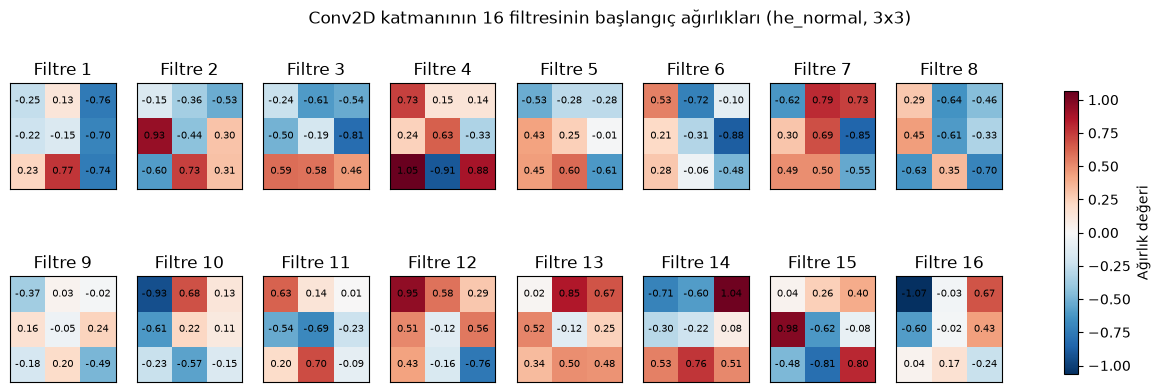

Ağırlık ortalaması: 0.0172  std: 0.5193  (beklenen he_normal std ≈ sqrt(2/9) = 0.4714)


In [3]:
# 7. Tüm 16 filtrenin başlangıç ağırlıklarının görselleştirilmesi
fig, axes = plt.subplots(2, 8, figsize=(16, 4.6))
vmax = np.abs(weights).max()
for i, ax in enumerate(axes.flat):
    w = weights[:, :, 0, i]
    im = ax.imshow(w, cmap='RdBu_r', vmin=-vmax, vmax=vmax)
    for (r, c), val in np.ndenumerate(w):
        ax.text(c, r, f"{val:.2f}", ha='center', va='center', fontsize=7)
    ax.set_title(f"Filtre {i+1}")
    ax.set_xticks([]); ax.set_yticks([])
fig.colorbar(im, ax=axes, shrink=0.8, label="Ağırlık değeri")
fig.suptitle("Conv2D katmanının 16 filtresinin başlangıç ağırlıkları (he_normal, 3x3)")
plt.savefig("ciktilar/1_filtre_agirliklari.png", dpi=150, bbox_inches='tight')
plt.show()

print("Ağırlık ortalaması: %.4f  std: %.4f  (beklenen he_normal std ≈ sqrt(2/9) = %.4f)"
      % (weights.mean(), weights.std(), np.sqrt(2/9)))

Kırmızı hücreler pozitif, mavi hücreler negatif ağırlıkları gösterir. Filtreler henüz eğitilmediği için belirgin bir desen yoktur; tamamen rastgeledir. Ek olarak, bu filtrelerin rastgele giriş üzerinde ürettiği özellik haritalarından birkaçı aşağıda gösterilmiştir (ReLU nedeniyle negatif bölgeler 0'a, yani siyaha dönmüştür).

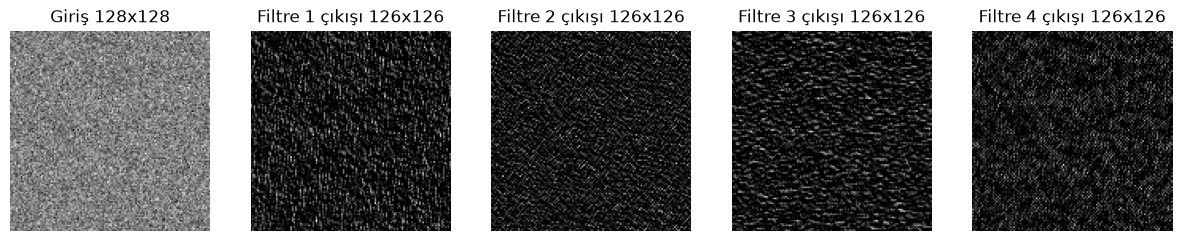

In [4]:
fig, axes = plt.subplots(1, 5, figsize=(15, 3.2))
axes[0].imshow(dummy_input[0, :, :, 0], cmap='gray'); axes[0].set_title("Giriş 128x128")
for k in range(4):
    axes[k+1].imshow(output[0, :, :, k], cmap='gray'); axes[k+1].set_title(f"Filtre {k+1} çıkışı 126x126")
for ax in axes: ax.axis('off')
plt.savefig("ciktilar/2_ozellik_haritalari.png", dpi=150, bbox_inches='tight')
plt.show()

## 4. Bölüm: Pooling işleminin incelenmesi

In [5]:
import tensorflow as tf

# Örnek giriş matrisi
input_data = tf.constant([
    [1., 3., 2., 4.],
    [5., 6., 1., 2.],
    [7., 2., 8., 3.],
    [4., 1., 5., 9.]
])

# Boyutları düzenle: Batch, Height, Width, Channels
input_data = tf.reshape(input_data, (1, 4, 4, 1))

pool = tf.keras.layers.MaxPooling2D(
    pool_size=(2, 2),
    strides=2
)

output = pool(input_data)

print("Giriş:")
print(input_data.numpy()[0, :, :, 0])

print("Pooling sonucu:")
print(output.numpy()[0, :, :, 0])

print("Giriş boyutu:", input_data.shape, " Çıkış boyutu:", output.shape)

Giriş:
[[1. 3. 2. 4.]
 [5. 6. 1. 2.]
 [7. 2. 8. 3.]
 [4. 1. 5. 9.]]
Pooling sonucu:
[[6. 4.]
 [7. 9.]]
Giriş boyutu: (1, 4, 4, 1)  Çıkış boyutu: (1, 2, 2, 1)


### Yapılacak çalışmalar – cevaplar

**1. Giriş matrisini inceleyiniz.**
4×4'lük tek kanallı bir matristir. `reshape` ile (1, 4, 4, 1) yapılarak Keras'ın beklediği (Batch, Yükseklik, Genişlik, Kanal) formatına getirilmiştir. Matris stride=2 ile örtüşmeyen dört adet 2×2 bölgeye ayrılır:

| | Sol sütunlar | Sağ sütunlar |
|---|---|---|
| **Üst satırlar** | 1, 3, 5, 6 | 2, 4, 1, 2 |
| **Alt satırlar** | 7, 2, 4, 1 | 8, 3, 5, 9 |

**2. Her 2×2 bölgedeki en büyük sayı (elle hesap):**
- Sol üst: max(1, 3, 5, 6) = **6**
- Sağ üst: max(2, 4, 1, 2) = **4**
- Sol alt: max(7, 2, 4, 1) = **7**
- Sağ alt: max(8, 3, 5, 9) = **9**

Elle hesaplanan sonuç: $\begin{bmatrix} 6 & 4 \\ 7 & 9 \end{bmatrix}$

**3. Programın sonucu ile karşılaştırma:** Program da `[[6. 4.] [7. 9.]]` çıktısını üretmiştir; elle yapılan hesapla **birebir aynıdır** (aşağıdaki kod hücresi bunu otomatik olarak da doğrular).

**4. Giriş ve çıkış boyutları:** Giriş (1, 4, 4, 1), çıkış (1, 2, 2, 1). Yükseklik ve genişlik yarıya inmiş, batch ve kanal sayısı değişmemiştir. Formül: $(4 - 2)/2 + 1 = 2$. 16 değerden 4 değer kalmıştır (%75 azalma).

**5. Max Pooling kullanılmasının CNN açısından avantajı nedir?**
- Özellik haritasını küçülterek sonraki katmanların hesaplama yükünü ve Dense katmana giden parametre sayısını ciddi oranda azaltır.
- Her bölgedeki en güçlü aktivasyonu (en belirgin özelliği) korur, zayıf yanıtları atar.
- Nesne birkaç piksel kaysa bile maksimum değer genellikle aynı kaldığı için küçük kaymalara/bozulmalara karşı dayanıklılık sağlar.
- Sonraki filtrelerin görüş alanını (receptive field) büyütür; böylece derin katmanlar görüntünün daha geniş bölgelerini görür.
- Öğrenilecek parametresi yoktur ve aşırı öğrenmeyi azaltmaya katkı sağlar.

Elle hesap ile aynı mı? True


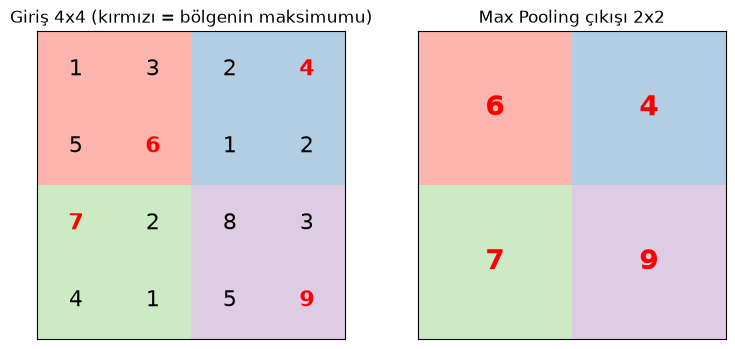

In [6]:
# Elle hesap ile programın çıktısının otomatik karşılaştırılması + görselleştirme
elle = np.array([[6., 4.], [7., 9.]])
print("Elle hesap ile aynı mı?", np.array_equal(elle, output.numpy()[0, :, :, 0]))

giris = input_data.numpy()[0, :, :, 0]; cikis = output.numpy()[0, :, :, 0]
renk = np.array([[0, 0, 1, 1], [0, 0, 1, 1], [2, 2, 3, 3], [2, 2, 3, 3]])
fig, ax = plt.subplots(1, 2, figsize=(9, 4))
ax[0].imshow(renk, cmap='Pastel1', vmin=0, vmax=8)
for (r, c), v in np.ndenumerate(giris):
    kalin = v == cikis[r // 2, c // 2]
    ax[0].text(c, r, int(v), ha='center', va='center', fontsize=16,
               fontweight='bold' if kalin else 'normal', color='red' if kalin else 'black')
ax[0].set_title("Giriş 4x4 (kırmızı = bölgenin maksimumu)")
ax[1].imshow(np.array([[0, 1], [2, 3]]), cmap='Pastel1', vmin=0, vmax=8)
for (r, c), v in np.ndenumerate(cikis):
    ax[1].text(c, r, int(v), ha='center', va='center', fontsize=20, fontweight='bold', color='red')
ax[1].set_title("Max Pooling çıkışı 2x2")
for a in ax: a.set_xticks([]); a.set_yticks([])
plt.savefig("ciktilar/3_max_pooling.png", dpi=150, bbox_inches='tight')
plt.show()

## 5. Bölüm: ReLU ve Softmax fonksiyonlarının incelenmesi
### A. ReLU

In [7]:
import tensorflow as tf

x = tf.constant([-5., -2., -1., 0., 2., 4., 6.])
relu = tf.keras.layers.ReLU()
y = relu(x)
print("Giriş:", x.numpy())
print("ReLU çıkışı:", y.numpy())

Giriş: [-5. -2. -1.  0.  2.  4.  6.]
ReLU çıkışı: [0. 0. 0. 0. 2. 4. 6.]


**Negatif değerler neden sıfırlanmıştır?**
ReLU'nun tanımı $f(x) = \max(0, x)$ olduğu için 0'dan küçük her sayı için 0 ile sayının kendisinden büyük olan, yani 0 seçilir: −5, −2, −1 → 0. Bunun anlamı, nöronun ilgili özelliği "görmediği" durumda sessiz kalmasıdır. Bu, ağda seyrek (sparse) aktivasyonlar oluşturur ve hesaplamayı verimli kılar.

**Pozitif değerler neden korunmuştur?**
Pozitif sayılar için $\max(0, x) = x$ olduğundan 2, 4, 6 değişmeden geçer. Böylece sinyalin büyüklüğü (özelliğin ne kadar güçlü bulunduğu) korunur; pozitif bölgede türev 1 olduğu için gradyan geri yayılımda küçülmeden aktarılır ve **kaybolan gradyan** sorunu yaşanmaz. 0 değeri ise 0 olarak kalır.

**ReLU kullanılmasaydı ne gibi bir farklılık oluşabilirdi?**
Hiç aktivasyon kullanılmasaydı tüm katmanlar tek bir doğrusal dönüşüme indirgenir, ağ karmaşık desenleri öğrenemezdi. ReLU yerine sigmoid/tanh kullanılsaydı bu fonksiyonlar büyük değerlerde doyuma ulaşıp türevleri 0'a yaklaştığı için derin ağlarda gradyanlar kaybolur, eğitim çok yavaşlar ve hesaplama (üstel fonksiyon) daha maliyetli olurdu. Ayrıca negatif değerler sıfırlanmadığı için çıkışta "−5" gibi anlamsız negatif aktivasyonlar sonraki katmanlara taşınmaya devam ederdi.

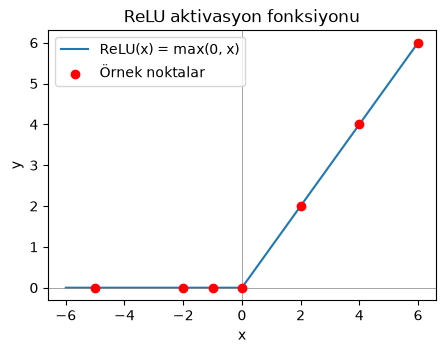

In [8]:
# ReLU grafiği
xs = np.linspace(-6, 6, 200)
plt.figure(figsize=(5, 3.5))
plt.plot(xs, np.maximum(0, xs), label="ReLU(x) = max(0, x)")
plt.scatter(x.numpy(), y.numpy(), color='red', zorder=3, label="Örnek noktalar")
plt.axhline(0, color='gray', lw=0.5); plt.axvline(0, color='gray', lw=0.5)
plt.title("ReLU aktivasyon fonksiyonu"); plt.xlabel("x"); plt.ylabel("y"); plt.legend()
plt.savefig("ciktilar/4_relu.png", dpi=150, bbox_inches='tight')
plt.show()

### B. Softmax

In [9]:
import tensorflow as tf

logits = tf.constant([[2.0, 1.0, 0.1]])
softmax = tf.keras.layers.Softmax()
probabilities = softmax(logits)
print("Softmax sonuçları:")
print(probabilities.numpy())
print("Olasılıkların toplamı:")
print(tf.reduce_sum(probabilities).numpy())

# Elle doğrulama
e = np.exp([2.0, 1.0, 0.1])
print("Elle hesap: e^z =", e.round(4), " toplam =", e.sum().round(4), " -> olasılıklar =", (e / e.sum()).round(4))
print("En olası sınıf indeksi:", tf.argmax(probabilities, axis=1).numpy()[0])

Softmax sonuçları:
[[0.6590011  0.24243298 0.09856588]]
Olasılıkların toplamı:
0.99999994
Elle hesap: e^z = [7.3891 2.7183 1.1052]  toplam = 11.2125  -> olasılıklar = [0.659  0.2424 0.0986]
En olası sınıf indeksi: 0


**Elle hesap:** $e^{2.0} = 7.389$, $e^{1.0} = 2.718$, $e^{0.1} = 1.105$; toplam = 11.212.
Olasılıklar: 7.389/11.212 = **0.659**, 2.718/11.212 = **0.242**, 1.105/11.212 = **0.099** → program çıktısıyla aynıdır.

**Softmax hangi amaçla kullanılır?**
Çok sınıflı sınıflandırma problemlerinde ağın son katmanındaki ham skorları (logit) yorumlanabilir sınıf olasılıklarına dönüştürmek için kullanılır. Ayrıca `sparse_categorical_crossentropy` gibi kayıp fonksiyonları olasılık dağılımı beklediği için eğitimin de parçasıdır.

**Çıktıdaki değerler neyi ifade etmektedir?**
Her değer, girişin ilgili sınıfa ait olma olasılığıdır: 1. sınıf %65.9, 2. sınıf %24.2, 3. sınıf %9.9. Üstel fonksiyon farkları büyüttüğü için en yüksek logit (2.0) orantısal olarak daha da baskın hale gelmiştir (logit oranı 2:1 iken olasılık oranı ≈ 2.7:1).

**Olasılıkların toplamı neden 1'dir?**
Çünkü her eleman $e^{z_i}$ değeri, tüm $e^{z_j}$'lerin toplamına bölünerek normalize edilir: $\sum_i \frac{e^{z_i}}{\sum_j e^{z_j}} = \frac{\sum_i e^{z_i}}{\sum_j e^{z_j}} = 1$. Ayrıca $e^z$ her zaman pozitif olduğu için her olasılık 0 ile 1 arasındadır; bu da geçerli bir olasılık dağılımı oluşturur. (Çıktıda 1.0'dan çok küçük sapma görülürse bu float32 yuvarlama hatasıdır.)

**En yüksek olasılığa sahip sınıf nasıl belirlenir?**
Olasılık vektöründeki en büyük değerin indeksi alınır: `np.argmax(probabilities)` veya `tf.argmax(probabilities, axis=1)`. Bu örnekte indeks **0** (olasılık 0.659) yani 1. sınıf tahmin edilir. Softmax sıralamayı değiştirmediği için argmax'ı doğrudan logitler üzerinde almak da aynı sonucu verir.

## 6. Bölüm: Basit bir CNN modeli oluşturulması
Fashion-MNIST; 10 giysi sınıfına ait 28×28 gri seviyeli 60.000 eğitim ve 10.000 test görüntüsünden oluşur. Amaç, görüntünün hangi giysi sınıfına ait olduğunu belirlemektir.

### A. Veri setinin yüklenmesi

In [10]:
import tensorflow as tf
import numpy as np
import matplotlib.pyplot as plt

(x_train, y_train), (x_test, y_test) = (
    tf.keras.datasets.fashion_mnist.load_data()
)
# Normalizasyon
x_train = x_train.astype("float32") / 255.0
x_test = x_test.astype("float32") / 255.0
# Kanal boyutu ekleme
x_train = x_train[..., np.newaxis]
x_test = x_test[..., np.newaxis]
print("Eğitim verisi:", x_train.shape)
print("Test verisi:", x_test.shape)

Eğitim verisi: (60000, 28, 28, 1)
Test verisi: (10000, 28, 28, 1)


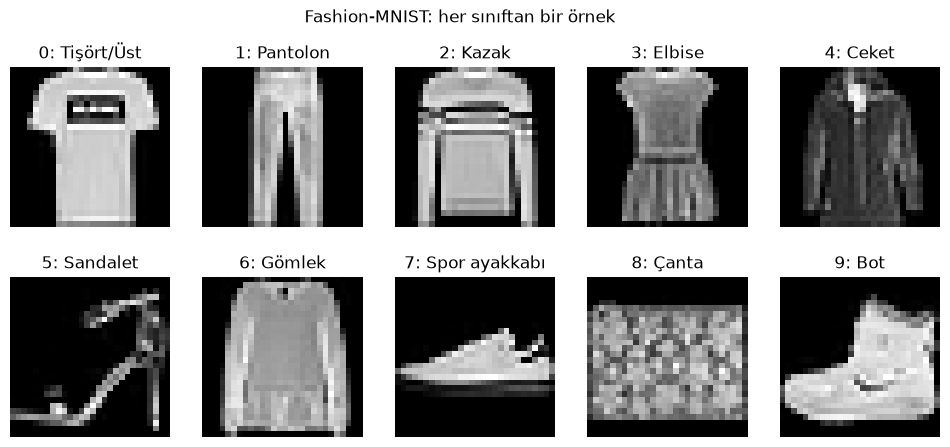

In [11]:
# Veri setinden örnekler
sinif_isimleri = ["Tişört/Üst", "Pantolon", "Kazak", "Elbise", "Ceket",
                  "Sandalet", "Gömlek", "Spor ayakkabı", "Çanta", "Bot"]
fig, axes = plt.subplots(2, 5, figsize=(12, 5))
for k, ax in enumerate(axes.flat):
    idx = np.where(y_train == k)[0][0]
    ax.imshow(x_train[idx, :, :, 0], cmap='gray'); ax.set_title(f"{k}: {sinif_isimleri[k]}"); ax.axis('off')
plt.suptitle("Fashion-MNIST: her sınıftan bir örnek")
plt.savefig("ciktilar/5_veri_ornekleri.png", dpi=150, bbox_inches='tight')
plt.show()

Pikseller 0–255 aralığından 0–1 aralığına normalize edilmiştir; bu, gradyanların dengeli olmasını ve eğitimin daha hızlı yakınsamasını sağlar. `np.newaxis` ile kanal boyutu eklenerek (60000, 28, 28) → (60000, 28, 28, 1) yapılmıştır, çünkü Conv2D (Yükseklik, Genişlik, Kanal) formatında giriş bekler.

### B. CNN mimarisinin oluşturulması

In [12]:
tf.keras.utils.set_random_seed(42)   # Tekrarlanabilir sonuç için

model = tf.keras.Sequential([
    tf.keras.layers.Input(shape=(28, 28, 1)),
    # Birinci konvolüsyon
    tf.keras.layers.Conv2D(
        8, (3, 3),
        activation='relu'
    ),
    # Birinci pooling
    tf.keras.layers.MaxPooling2D((2, 2)),
    # İkinci konvolüsyon
    tf.keras.layers.Conv2D(
        16, (3, 3),
        activation='relu'
    ),
    # İkinci pooling
    tf.keras.layers.MaxPooling2D((2, 2)),
    # Çok boyutlu özellikleri tek boyuta dönüştür
    tf.keras.layers.Flatten(),
    # Tam bağlantılı katman
    tf.keras.layers.Dense(64, activation='relu'),
    # 10 sınıf için çıktı
    tf.keras.layers.Dense(10, activation='softmax')
])
model.summary()

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ conv2d_1 (Conv2D)               │ (None, 26, 26, 8)      │            80 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_1 (MaxPooling2D)  │ (None, 13, 13, 8)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_2 (Conv2D)               │ (None, 11, 11, 16)     │         1,168 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_2 (MaxPooling2D)  │ (None, 5, 5, 16)       │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten (Flatten)               │ (None, 400)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 64)             │        25,664 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 10)             │           650 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 27,562 (107.66 KB)

 Trainable params: 27,562 (107.66 KB)

 Non-trainable params: 0 (0.00 B)

**Katman katman boyut ve parametre hesabı (elle):**

| Katman | Çıkış boyutu | Parametre hesabı | Parametre |
|---|---|---|---|
| Input | 28×28×1 | – | 0 |
| Conv2D (8, 3×3) | 26×26×8 | 3·3·1·8 + 8 | 80 |
| MaxPooling2D | 13×13×8 | – | 0 |
| Conv2D (16, 3×3) | 11×11×16 | 3·3·8·16 + 16 | 1.168 |
| MaxPooling2D | 5×5×16 | – | 0 |
| Flatten | 400 | – | 0 |
| Dense (64) | 64 | 400·64 + 64 | 25.664 |
| Dense (10) | 10 | 64·10 + 10 | 650 |
| **Toplam** | | | **27.562** |

Bu değerler `model.summary()` çıktısıyla örtüşmektedir. Parametrelerin yaklaşık %93'ünün ilk Dense katmanda olduğuna dikkat edilmelidir; konvolüsyon katmanları ağırlık paylaşımı sayesinde çok az parametreyle çalışır.

### C. Modelin derlenmesi ve eğitilmesi

In [13]:
model.compile(
    optimizer='adam',
    loss='sparse_categorical_crossentropy',
    metrics=['accuracy']
)

baslangic = time.time()
history = model.fit(
    x_train,
    y_train,
    epochs=5,
    batch_size=64,
    validation_split=0.1,
    verbose=2   # her epoch için tek satır çıktı
)
egitim_suresi = time.time() - baslangic

test_loss, test_accuracy = model.evaluate(
    x_test,
    y_test,
    verbose=0
)

print("Test Loss:", test_loss)
print("Test Accuracy:", test_accuracy)
print("Eğitim süresi: %.1f sn" % egitim_suresi)

Epoch 1/5


844/844 - 8s - 10ms/step - accuracy: 0.7696 - loss: 0.6286 - val_accuracy: 0.8207 - val_loss: 0.4820


Epoch 2/5


844/844 - 4s - 5ms/step - accuracy: 0.8472 - loss: 0.4236 - val_accuracy: 0.8437 - val_loss: 0.4257


Epoch 3/5


844/844 - 5s - 6ms/step - accuracy: 0.8647 - loss: 0.3754 - val_accuracy: 0.8590 - val_loss: 0.3877


Epoch 4/5


844/844 - 5s - 6ms/step - accuracy: 0.8757 - loss: 0.3450 - val_accuracy: 0.8683 - val_loss: 0.3590


Epoch 5/5


844/844 - 5s - 6ms/step - accuracy: 0.8824 - loss: 0.3227 - val_accuracy: 0.8763 - val_loss: 0.3364


Test Loss: 0.3588152229785919
Test Accuracy: 0.8726999759674072
Eğitim süresi: 27.0 sn


- **optimizer='adam':** Her ağırlık için öğrenme oranını otomatik ayarlayan, hızlı yakınsayan bir gradyan iniş yöntemi.
- **loss='sparse_categorical_crossentropy':** Etiketler 0–9 arası tam sayı (one-hot değil) olduğu için kullanılan çok sınıflı çapraz entropi kaybı.
- **metrics=['accuracy']:** Doğru tahmin edilen örneklerin oranı.
- **epochs=5:** Eğitim verisinin tamamı 5 kez dolaşılır. **batch_size=64:** Ağırlıklar her 64 örnekte bir güncellenir (54.000 / 64 ≈ 844 adım/epoch). **validation_split=0.1:** Eğitim verisinin son %10'u (6.000 görüntü) eğitimde kullanılmayıp her epoch sonunda doğrulama için ayrılır.

### D. Eğitim sonuçlarının görselleştirilmesi

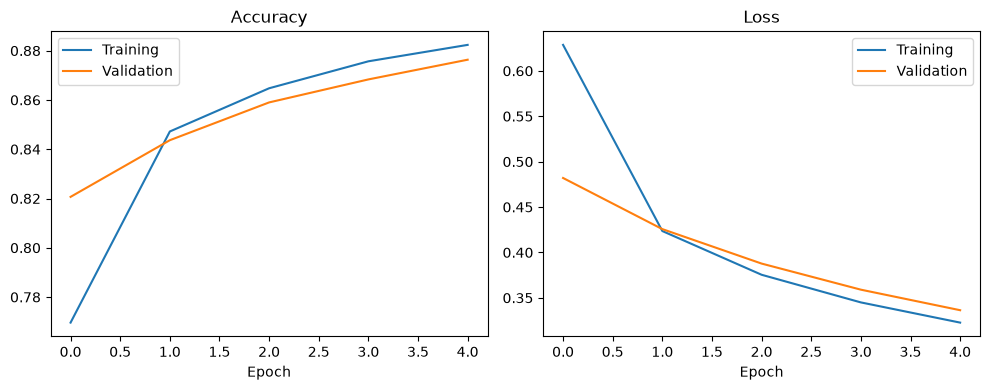

In [14]:
import matplotlib.pyplot as plt

plt.figure(figsize=(10, 4))

plt.subplot(1, 2, 1)
plt.plot(history.history['accuracy'], label='Training')
plt.plot(history.history['val_accuracy'], label='Validation')
plt.title('Accuracy')
plt.xlabel('Epoch')
plt.legend()

plt.subplot(1, 2, 2)
plt.plot(history.history['loss'], label='Training')
plt.plot(history.history['val_loss'], label='Validation')
plt.title('Loss')
plt.xlabel('Epoch')
plt.legend()

plt.tight_layout()
plt.savefig("ciktilar/6_egitim_grafikleri.png", dpi=150, bbox_inches='tight')
plt.show()

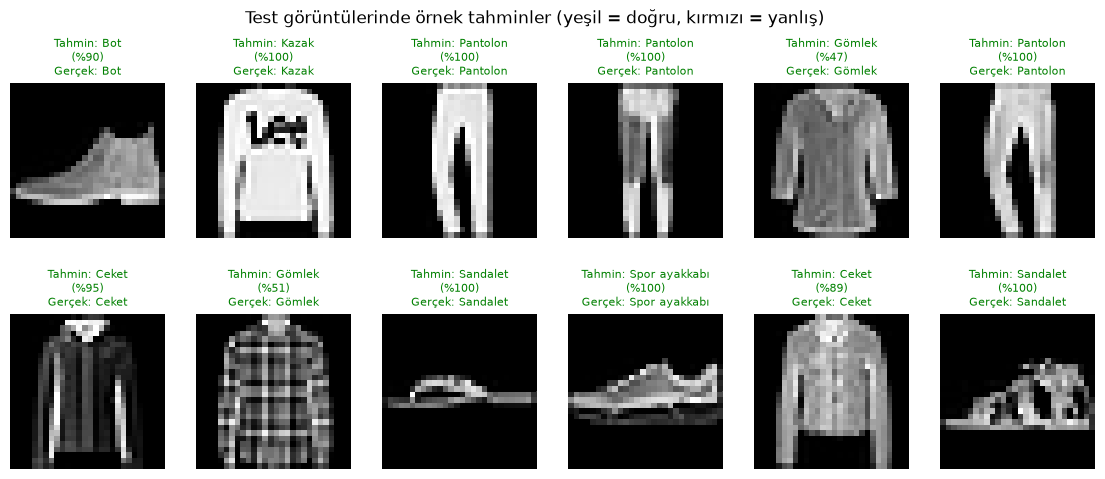

Sınıf bazında test doğruluğu:
  0 Tişört/Üst    : %90.7
  1 Pantolon      : %96.6
  2 Kazak         : %84.5
  3 Elbise        : %92.2
  4 Ceket         : %80.1
  5 Sandalet      : %96.1
  6 Gömlek        : %47.5
  7 Spor ayakkabı : %97.3
  8 Çanta         : %96.5
  9 Bot           : %91.2


In [15]:
# Model test sonuçları: örnek tahminler ve sınıf bazında doğruluk
olasiliklar = model.predict(x_test, verbose=0)
tahminler = np.argmax(olasiliklar, axis=1)

fig, axes = plt.subplots(2, 6, figsize=(14, 5.5))
for i, ax in enumerate(axes.flat):
    ax.imshow(x_test[i, :, :, 0], cmap='gray'); ax.axis('off')
    dogru = tahminler[i] == y_test[i]
    ax.set_title(f"Tahmin: {sinif_isimleri[tahminler[i]]}\n(%{100*olasiliklar[i].max():.0f})\nGerçek: {sinif_isimleri[y_test[i]]}",
                 fontsize=8, color='green' if dogru else 'red')
plt.suptitle("Test görüntülerinde örnek tahminler (yeşil = doğru, kırmızı = yanlış)")
plt.savefig("ciktilar/7_ornek_tahminler.png", dpi=150, bbox_inches='tight')
plt.show()

print("Sınıf bazında test doğruluğu:")
for k in range(10):
    m = y_test == k
    print(f"  {k} {sinif_isimleri[k]:<14}: %{100*np.mean(tahminler[m] == k):.1f}")

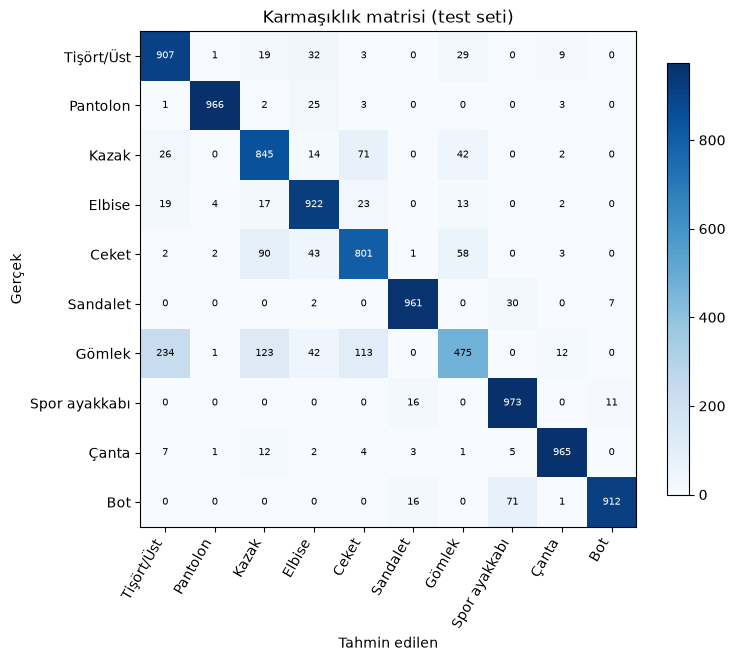

In [16]:
# Karmaşıklık matrisi (confusion matrix)
cm = tf.math.confusion_matrix(y_test, tahminler, num_classes=10).numpy()
plt.figure(figsize=(8, 7))
plt.imshow(cm, cmap='Blues')
for (r, c), v in np.ndenumerate(cm):
    plt.text(c, r, v, ha='center', va='center', fontsize=7, color='white' if v > cm.max()/2 else 'black')
plt.xticks(range(10), sinif_isimleri, rotation=60, ha='right'); plt.yticks(range(10), sinif_isimleri)
plt.xlabel("Tahmin edilen"); plt.ylabel("Gerçek"); plt.title("Karmaşıklık matrisi (test seti)")
plt.colorbar(shrink=0.8)
plt.savefig("ciktilar/8_karmasiklik_matrisi.png", dpi=150, bbox_inches='tight')
plt.show()

## 7. Bölüm: Model mimarisinin anlaşılması

**1. Modelde kaç adet konvolüsyon katmanı vardır?**
**2** adet Conv2D katmanı vardır (8 filtreli ve 16 filtreli). Bunların yanında 2 MaxPooling, 1 Flatten ve 2 Dense katman bulunur.

**2. İlk konvolüsyon katmanında neden 8 filtre kullanılmıştır?**
İlk katman kenar, çizgi, köşe gibi basit ve düşük seviyeli özellikleri öğrenir. Fashion-MNIST gri seviyeli, düşük çözünürlüklü (28×28) ve görece basit bir veri seti olduğu için bu temel özellikleri yakalamak için az sayıda filtre yeterlidir. Az filtre aynı zamanda hesaplama maliyetini ve parametre sayısını (yalnızca 80) düşük tutar; bu, öğretim amaçlı küçük ve hızlı bir model için uygun bir seçimdir.

**3. İkinci konvolüsyon katmanında neden 16 filtre kullanılmıştır?**
İkinci katman, ilk katmanın bulduğu basit özellikleri birleştirerek daha karmaşık desenler (yaka, kol, taban, sap gibi parçalar) öğrenir. Karmaşık desenlerin kombinasyon sayısı daha fazla olduğundan daha çok filtreye ihtiyaç vardır. Ayrıca pooling ile uzamsal boyut küçüldüğü için filtre sayısını artırmak hesaplama yükünü dengeler; CNN'lerde derine inildikçe filtre sayısını artırmak (8 → 16 → 32...) yaygın bir tasarım prensibidir: **boyut küçülür, derinlik artar**.

**4. Konvolüsyon katmanlarından sonra görüntü boyutları nasıl değişmiştir?**
28×28×1 → (Conv 3×3) **26×26×8** → (Pool) 13×13×8 → (Conv 3×3) **11×11×16** → (Pool) 5×5×16. Her 3×3 'valid' konvolüsyon yükseklik ve genişliği 2 piksel azaltır, kanal sayısını filtre sayısına eşitler.

**5. Pooling katmanları ne gibi bir katkı sağlamıştır?**
Her biri boyutu yarıya indirerek (26→13, 11→5) veri miktarını yaklaşık 4 kat azaltmıştır. Pooling olmasaydı ikinci konvolüsyon çıkışı 24×24×16 = 9.216 eleman olur ve ilk Dense katmanı 9.216·64 + 64 ≈ **590.000** parametre içerirdi; pooling sayesinde bu sayı **25.664**'te kalmıştır (yaklaşık 23 kat daha az). Böylece model hem daha hızlı eğitilmiş hem de aşırı öğrenme riski azalmış, küçük kaymalara karşı da dayanıklılık kazanmıştır.

**6. Flatten katmanının çıktısı kaç elemanlıdır?**
5 × 5 × 16 = **400** eleman.

**7. Dense katmanındaki 64 sayısı neyi ifade etmektedir?**
Bu tam bağlantılı katmanda **64 nöron** bulunduğunu ifade eder. Her nöron Flatten'den gelen 400 değerin tamamına bağlıdır (400 ağırlık + 1 bias) ve konvolüsyon katmanlarının çıkardığı özelliklerden 64 boyutlu daha soyut bir temsil oluşturur. Bu sayı bir hiperparametredir; modelin sınıflandırma kapasitesini belirler.

**8. Son katmanda neden 10 nöron bulunmaktadır?**
Fashion-MNIST'te **10 sınıf** (Tişört, Pantolon, Kazak, Elbise, Ceket, Sandalet, Gömlek, Spor ayakkabı, Çanta, Bot) vardır. Her nöron bir sınıfa karşılık gelir ve softmax ile o sınıfın olasılığını üretir.

**9. Softmax çıkışındaki en yüksek değer neyi ifade eder?**
Modelin tahmin ettiği sınıfı ve bu tahmine olan güvenini ifade eder. En yüksek olasılığa sahip nöronun indeksi (argmax) tahmin edilen sınıftır; değerin kendisi (ör. 0.97) modelin o sınıftan ne kadar emin olduğunu gösterir.

**10. Modelin tahmin başarısını hangi metrikle ölçtünüz?**
**Doğruluk (accuracy)** metriği ile ölçülmüştür: doğru sınıflandırılan örnek sayısının toplam örnek sayısına oranı. Eğitim sırasında eğitim ve doğrulama (validation) doğruluğu, sonunda ise modelin hiç görmediği 10.000 görüntülük test setindeki doğruluk raporlanmıştır. Bunun yanında kayıp (sparse categorical cross-entropy) değeri, sınıf bazında doğruluk ve karmaşıklık matrisi de incelenmiştir.

## 8. Bölüm: Küçük bir deney
Aynı model iki farklı konfigürasyonla eğitilmiştir. **Deney 1:** ilk konvolüsyon katmanında 8 filtre, **Deney 2:** 16 filtre. Diğer tüm parametreler (mimari, optimizer, epoch=5, batch_size=64, validation_split=0.1, rastgelelik tohumu=42) aynı tutulmuştur. Adil karşılaştırma için iki deney de aynı fonksiyonla, aynı tohumla sıfırdan eğitilmiştir.

In [17]:
def model_olustur(ilk_filtre_sayisi):
    return tf.keras.Sequential([
        tf.keras.layers.Input(shape=(28, 28, 1)),
        tf.keras.layers.Conv2D(ilk_filtre_sayisi, (3, 3), activation='relu'),
        tf.keras.layers.MaxPooling2D((2, 2)),
        tf.keras.layers.Conv2D(16, (3, 3), activation='relu'),
        tf.keras.layers.MaxPooling2D((2, 2)),
        tf.keras.layers.Flatten(),
        tf.keras.layers.Dense(64, activation='relu'),
        tf.keras.layers.Dense(10, activation='softmax')
    ])

def deney_yap(ilk_filtre_sayisi):
    tf.keras.utils.set_random_seed(42)
    m = model_olustur(ilk_filtre_sayisi)
    m.compile(optimizer='adam', loss='sparse_categorical_crossentropy', metrics=['accuracy'])
    t0 = time.time()
    h = m.fit(x_train, y_train, epochs=5, batch_size=64, validation_split=0.1, verbose=2)
    sure = time.time() - t0
    _, test_acc = m.evaluate(x_test, y_test, verbose=0)
    return {"filtre": ilk_filtre_sayisi,
            "parametre": int(m.count_params()),
            "egitim_dogrulugu": float(h.history['accuracy'][-1]),
            "dogrulama_dogrulugu": float(h.history['val_accuracy'][-1]),
            "test_dogrulugu": float(test_acc),
            "sure": sure,
            "gecmis": h.history}

print("=== Deney 1: ilk katmanda 8 filtre ===")
deney1 = deney_yap(8)
print("\n=== Deney 2: ilk katmanda 16 filtre ===")
deney2 = deney_yap(16)

with open("ciktilar/deney_sonuclari.json", "w", encoding="utf-8") as f:
    json.dump([{k: v for k, v in d.items() if k != "gecmis"} for d in (deney1, deney2)], f, indent=2)

=== Deney 1: ilk katmanda 8 filtre ===
Epoch 1/5


844/844 - 6s - 7ms/step - accuracy: 0.7696 - loss: 0.6286 - val_accuracy: 0.8207 - val_loss: 0.4820


Epoch 2/5


844/844 - 4s - 5ms/step - accuracy: 0.8472 - loss: 0.4236 - val_accuracy: 0.8437 - val_loss: 0.4257


Epoch 3/5


844/844 - 4s - 5ms/step - accuracy: 0.8647 - loss: 0.3754 - val_accuracy: 0.8590 - val_loss: 0.3877


... (10 outputs left out)

Epoch 4/5


844/844 - 6s - 7ms/step - accuracy: 0.8800 - loss: 0.3294 - val_accuracy: 0.8745 - val_loss: 0.3500


Epoch 5/5


844/844 - 5s - 6ms/step - accuracy: 0.8866 - loss: 0.3090 - val_accuracy: 0.8773 - val_loss: 0.3367


Ölçüt                      Deney 1     Deney 2
----------------------------------------------
Filtre sayısı                    8          16
Toplam parametre            27,562      28,794
Eğitim doğruluğu            0.8824      0.8866
Doğrulama doğruluğu         0.8763      0.8773
Test doğruluğu              0.8727      0.8761
Eğitim süresi (sn)            23.7        29.2


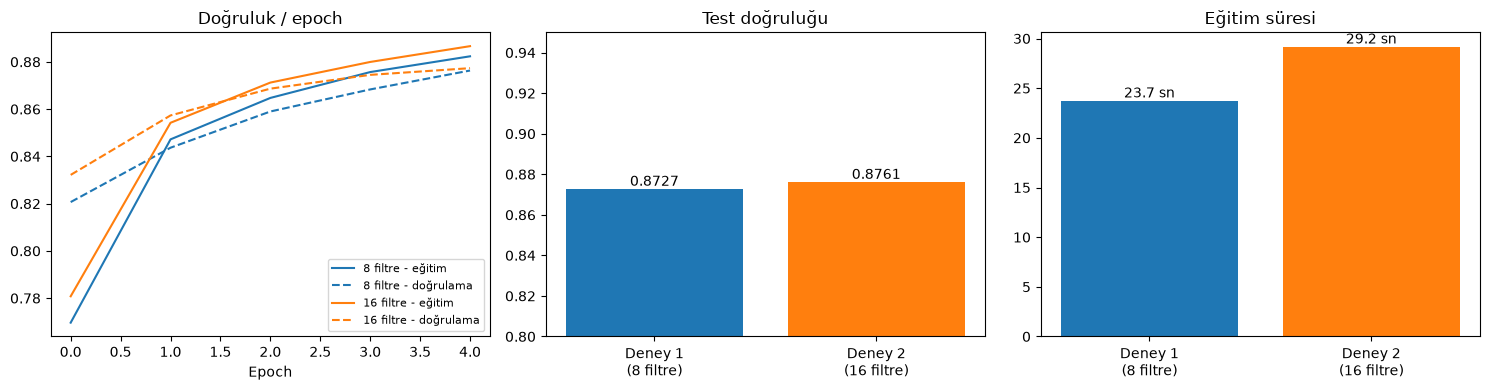

In [18]:
# Sonuç tablosu
satirlar = [("Filtre sayısı", "filtre", "{:d}"),
            ("Toplam parametre", "parametre", "{:,d}"),
            ("Eğitim doğruluğu", "egitim_dogrulugu", "{:.4f}"),
            ("Doğrulama doğruluğu", "dogrulama_dogrulugu", "{:.4f}"),
            ("Test doğruluğu", "test_dogrulugu", "{:.4f}"),
            ("Eğitim süresi (sn)", "sure", "{:.1f}")]
print(f"{'Ölçüt':<22}{'Deney 1':>12}{'Deney 2':>12}")
print("-" * 46)
for ad, anahtar, fmt in satirlar:
    print(f"{ad:<22}{fmt.format(deney1[anahtar]):>12}{fmt.format(deney2[anahtar]):>12}")

# Karşılaştırma grafikleri
fig, ax = plt.subplots(1, 3, figsize=(15, 4))
for d, renk in ((deney1, 'tab:blue'), (deney2, 'tab:orange')):
    ax[0].plot(d['gecmis']['accuracy'], color=renk, label=f"{d['filtre']} filtre - eğitim")
    ax[0].plot(d['gecmis']['val_accuracy'], '--', color=renk, label=f"{d['filtre']} filtre - doğrulama")
ax[0].set_title("Doğruluk / epoch"); ax[0].set_xlabel("Epoch"); ax[0].legend(fontsize=8)
etiket = ["Deney 1\n(8 filtre)", "Deney 2\n(16 filtre)"]
b = ax[1].bar(etiket, [deney1['test_dogrulugu'], deney2['test_dogrulugu']], color=['tab:blue', 'tab:orange'])
ax[1].bar_label(b, fmt="%.4f"); ax[1].set_ylim(0.8, 0.95); ax[1].set_title("Test doğruluğu")
b = ax[2].bar(etiket, [deney1['sure'], deney2['sure']], color=['tab:blue', 'tab:orange'])
ax[2].bar_label(b, fmt="%.1f sn"); ax[2].set_title("Eğitim süresi")
plt.tight_layout()
plt.savefig("ciktilar/9_deney_karsilastirma.png", dpi=150, bbox_inches='tight')
plt.show()

### Sonuç tablosu

| Ölçüt | Deney 1 | Deney 2 |
|---|---|---|
| Filtre sayısı (1. katman) | 8 | 16 |
| Toplam parametre | 27.562 | 28.794 |
| Eğitim doğruluğu (5. epoch) | 0,8824 | 0,8866 |
| Doğrulama doğruluğu | 0,8763 | 0,8773 |
| Test doğruluğu | 0,8727 | 0,8761 |
| Eğitim süresi | 23,7 sn | 29,2 sn |

*(Süreler CPU üzerinde ölçülmüştür; farklı bilgisayarlarda değişir.)*

### Yorum

**Filtre sayısının artırılması model başarısını nasıl etkilemiştir?**
İlk katmandaki filtre sayısı 8'den 16'ya çıkarıldığında test doğruluğu %87,27'den **%87,61**'e yükselmiştir; yani yalnızca **≈0,34 puanlık** küçük bir iyileşme olmuştur. Eğitim doğruluğu da benzer şekilde 0,4 puan artmıştır. Daha fazla filtre, ilk katmanın daha çeşitli kenar/doku desenleri yakalamasını sağladığı için model biraz daha iyi özellik çıkarabilmiştir. Buna karşılık parametre sayısı %4,5 (1.232 parametre), eğitim süresi ise yaklaşık **%23** artmıştır. İlk konvolüsyon katmanının çıkışı iki kat büyüdüğü (26×26×8 → 26×26×16) ve ikinci konvolüsyon artık 16 kanallı girişi işlediği için hesaplama yükü artmıştır.

Eğitim ve test doğrulukları birbirine yakın olduğundan (fark ≈ %1) her iki modelde de belirgin bir aşırı öğrenme (overfitting) görülmemiştir.

**Daha fazla filtre kullanılması her zaman daha iyi sonuç verir mi?**
**Hayır.** Bu deneyde de görüldüğü gibi filtre sayısını iki katına çıkarmak başarıyı orantılı olarak artırmamış, yalnızca çok küçük bir kazanç sağlamıştır (azalan getiri). Bunun nedenleri:
- **Veri setinin karmaşıklığı sınırlıdır:** 28×28 gri seviyeli görüntülerde ilk katmanda öğrenilebilecek anlamlı basit desen sayısı azdır; fazladan filtreler birbirine benzeyen (gereksiz) özellikler öğrenebilir.
- **Aşırı öğrenme riski:** Parametre sayısı arttıkça model eğitim verisini ezberlemeye daha yatkın hale gelir; özellikle az veri ile eğitimde test başarısı düşebilir.
- **Maliyet:** Filtre sayısı arttıkça bellek kullanımı, eğitim ve tahmin süresi artar. Mobil cihaz gibi kısıtlı ortamlarda bu önemli bir dezavantajdır.
- **Darboğaz başka yerde olabilir:** Bu modelde başarıyı sınırlayan esas etken "Gömlek" sınıfının Tişört/Kazak/Ceket ile karıştırılmasıdır (Gömlek sınıfı doğruluğu yalnızca ≈%47). Bu sorun ilk katmandaki filtre sayısından çok, modelin derinliği, epoch sayısı, veri artırma (augmentation) veya Dropout/BatchNormalization gibi tekniklerle ilgilidir.
- **Tek bir deneyin istatistiksel sınırı:** 0,34 puanlık fark, farklı rastgele tohumlarla tekrarlandığında değişebilecek kadar küçüktür; kesin bir sonuç için deney birden çok tohumla tekrarlanmalıdır.

Sonuç olarak filtre sayısı, doğruluk ile hesaplama maliyeti arasında denge kurularak, doğrulama verisi üzerinde denenerek seçilmesi gereken bir **hiperparametredir**.

## 9. Değerlendirme ve sonuç

Bu çalışmada bir CNN'in yapı taşları tek tek incelenmiş ve her biri kodla doğrulanmıştır:
- **Konvolüsyon** katmanında 16 adet 3×3 filtrenin (3, 3, 1, 16) boyutlu ağırlık ve (16,) boyutlu bias tensörü oluşturduğu, 'valid' dolgu nedeniyle 128×128 girişin 126×126'ya küçüldüğü görülmüş; he_normal ile başlatılan rastgele filtreler görselleştirilmiştir.
- **Max Pooling** işlemi elle hesaplanmış ([[6, 4], [7, 9]]) ve TensorFlow çıktısıyla birebir aynı olduğu doğrulanmıştır.
- **ReLU**'nun negatif değerleri sıfırlayıp pozitifleri koruduğu, **Softmax**'ın logitleri toplamı 1 olan olasılıklara ([0,659; 0,242; 0,099]) çevirdiği gösterilmiştir.
- Yalnızca **27.562 parametreli** küçük bir CNN, 5 epoch'ta (CPU'da ≈25 saniye) Fashion-MNIST test setinde **%87,3 doğruluk** elde etmiştir. Sınıf bazında en başarılı sınıflar Spor ayakkabı, Pantolon ve Çanta (%96–97), en zor sınıf ise üst giyim sınıflarına benzediği için Gömlek (%47,5) olmuştur.
- Filtre sayısı deneyinde, ilk katmanda filtreleri iki katına çıkarmanın yalnızca küçük bir doğruluk artışı (+0,34 puan) sağladığı, buna karşılık süreyi ≈%23 artırdığı görülmüştür.

**Kendi değerlendirmem:** Bu ödev sayesinde bir CNN'i "kara kutu" olarak kullanmak yerine her katmanın veriyi nasıl dönüştürdüğünü, boyutların ve parametre sayılarının elle nasıl hesaplandığını öğrendim. Özellikle pooling katmanlarının parametre sayısını ne kadar azalttığını (pooling olmasaydı ilk Dense katman ≈590 bin parametre olacaktı) hesaplamak, mimari tasarım kararlarının nedenini anlamamı sağladı. Deney kısmı ise "daha büyük model = daha iyi model" düşüncesinin her zaman doğru olmadığını, hiperparametrelerin deneyle ve maliyet göz önüne alınarak seçilmesi gerektiğini gösterdi. Modeli geliştirmek için ileride epoch sayısını artırmak, `padding='same'`, Dropout, BatchNormalization ve veri artırma tekniklerini denemek, sonuçları da birden fazla rastgele tohumla tekrarlamak istiyorum.